# Explainable AI i model governance

## Financial Decision Support System — interpretacja modelu Random Forest

Notebook analizuje zapisany artefakt XAI dla modelu **Random Forest** używanego
do prognozy stopy zwrotu w następnej sesji.

Celem notebooka jest:

- potwierdzenie provenance artefaktu i użytego zbioru danych;
- analiza globalnej ważności cech metodą SHAP;
- analiza lokalnego wyjaśnienia pojedynczej prognozy;
- porównanie Partial Dependence i Accumulated Local Effects;
- sprawdzenie zgodności rekonstrukcji SHAP z predykcją modelu;
- udokumentowanie ograniczeń interpretacyjnych i zasad model governance.

Notebook **nie oblicza ponownie SHAP, PDP ani ALE**. Korzysta z artefaktów
wygenerowanych przez backend, dzięki czemu pozostaje warstwą analityczną
i dokumentacyjną, a nie alternatywną implementacją logiki XAI.

## 1. Zasady metodologiczne

W tej analizie obowiązują następujące reguły:

- model został wytrenowany na zbiorze treningowym;
- wyjaśnienia dotyczą zbioru walidacyjnego;
- końcowy zbiór testowy pozostaje zamknięty;
- interpretacja modelu nie jest równoznaczna z identyfikacją zależności przyczynowych;
- SHAP opisuje wkład cech do predykcji modelu;
- PDP pokazuje średnią odpowiedź modelu przy zmianie wybranej cechy;
- ALE ogranicza część problemów PDP wynikających ze skorelowanych predyktorów.

Notebook nie służy do wyboru modelu na podstawie danych testowych.


In [25]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

In [26]:
def find_project_root(start: Path | None = None) -> Path:
    candidate = (start or Path.cwd()).resolve()

    for path in [candidate, *candidate.parents]:
        if (path / "pyproject.toml").exists() and (path / "backend").exists():
            return path

    raise FileNotFoundError(
        "Nie znaleziono katalogu głównego projektu z pyproject.toml i backend/."
    )


PROJECT_ROOT = find_project_root()
XAI_DIR = PROJECT_ROOT / "benchmark_results" / "xai" / "random_forest"
RESULT_PATH = XAI_DIR / "xai_result.json"

if not RESULT_PATH.exists():
    raise FileNotFoundError(
        f"Brak artefaktu XAI: {RESULT_PATH}. "
        "Najpierw wygeneruj benchmark XAI w backendzie."
    )

print("Project root:", PROJECT_ROOT)
print("XAI artifact:", RESULT_PATH)

Project root: project-root
XAI artifact: benchmark_results/xai/random_forest/xai_result.json


## 2. Ładowanie artefaktu XAI

Źródłem prawdy dla notebooka jest `xai_result.json` oraz odpowiadające mu pliki
CSV. Notebook sprawdza podstawową integralność artefaktu przed interpretacją.

In [27]:
with RESULT_PATH.open("r", encoding="utf-8") as file:
    xai_result = json.load(file)

required_top_level_keys = {
    "schema_version",
    "metadata",
    "methods",
    "local_shap",
    "global_shap",
    "partial_dependence",
    "accumulated_local_effects",
    "plots",
}

missing_keys = required_top_level_keys.difference(xai_result)

if missing_keys:
    raise ValueError(f"Brak wymaganych sekcji artefaktu XAI: {sorted(missing_keys)}")

metadata = xai_result["metadata"]

metadata_frame = pd.DataFrame(
    [{"Pole": key, "Wartość": value} for key, value in metadata.items()]
)

display(metadata_frame)

,Pole,Wartość
0,background_rows,100
1,effect_feature_count,4
2,explanation_split,validation
3,global_explanation_rows,400
4,local_actual,-0.159747
5,local_date,2022-06-12T00:00:00
6,local_prediction,0.00175
7,local_target_date,2022-06-13T00:00:00
8,local_ticker,BTC-USD
9,model_name,random_forest


## 3. Kontrola provenance i zamkniętego test splitu

Artefakt powinien potwierdzać, że:

- model został zbudowany na `training`;
- wyjaśnienia dotyczą `validation`;
- celem jest `next_session_simple_return`;
- analizowany model to `random_forest`.

Jeżeli którykolwiek z tych warunków nie jest spełniony, notebook zatrzymuje się,
ponieważ interpretacja dotyczyłaby innej konfiguracji niż przyjęta w projekcie.

In [28]:
assert metadata["training_split"] == "training"
assert metadata["explanation_split"] == "validation"
assert metadata["target_definition"] == "next_session_simple_return"
assert metadata["model_name"] == "random_forest"

print("Model:", metadata["model_name"])
print("Training split:", metadata["training_split"])
print("Explanation split:", metadata["explanation_split"])
print("Target:", metadata["target_definition"])
print("Global SHAP observations:", metadata["global_explanation_rows"])
print("Test split: zamknięty — nie jest używany przez artefakt XAI")

Model: random_forest
Training split: training
Explanation split: validation
Target: next_session_simple_return
Global SHAP observations: 400
Test split: zamknięty — nie jest używany przez artefakt XAI


## 4. Globalna interpretacja modelu — SHAP

Globalne wyjaśnienie pokazuje, które cechy miały największy średni wpływ
na predykcje modelu Random Forest.

Wartość:

\[
mean(|SHAP|)
\]

oznacza średni bezwzględny wpływ danej cechy na wynik modelu.

Interpretacja:

- większa wartość oznacza większy wpływ na decyzje modelu;
- znak wpływu nie jest widoczny w tej metryce;
- ranking nie oznacza zależności przyczynowej;
- cecha może być ważna dlatego, że model wykorzystuje jej informację,
  a nie dlatego, że sama powoduje zmianę zwrotu.

In [29]:
global_shap = xai_result["global_shap"]

global_importance = pd.DataFrame(
    {
        "feature": list(global_shap["mean_absolute_contributions"].keys()),
        "mean_absolute_shap_value": list(
            global_shap["mean_absolute_contributions"].values()
        ),
    }
)

global_importance = global_importance.sort_values(
    by="mean_absolute_shap_value",
    ascending=False,
).reset_index(drop=True)

display(global_importance)

,feature,mean_absolute_shap_value
0,adjusted_close_to_ma_20,1.854329e-04
1,momentum_20,1.818332e-04
2,adjusted_close_to_ma_5,1.099974e-04
3,open_to_close_return,9.722467e-05
4,ticker_BTC-USD,8.090953e-05
5,daily_return,6.526976e-05
6,volatility_5,5.830644e-05
7,intraday_range,5.220481e-05
8,momentum_5,5.111126e-05
9,volume_change,3.296137e-05


## Ranking cech według średniego wpływu SHAP

Pierwsze pozycje rankingu pokazują cechy, które model najczęściej wykorzystywał
podczas generowania prognoz dla zbioru walidacyjnego.

W przypadku cech technicznych należy pamiętać, że:

- wskaźniki mogą zawierać podobną informację;
- korelacja między cechami może rozdzielać wpływ pomiędzy wiele zmiennych;
- ranking SHAP opisuje model, a nie rynek.

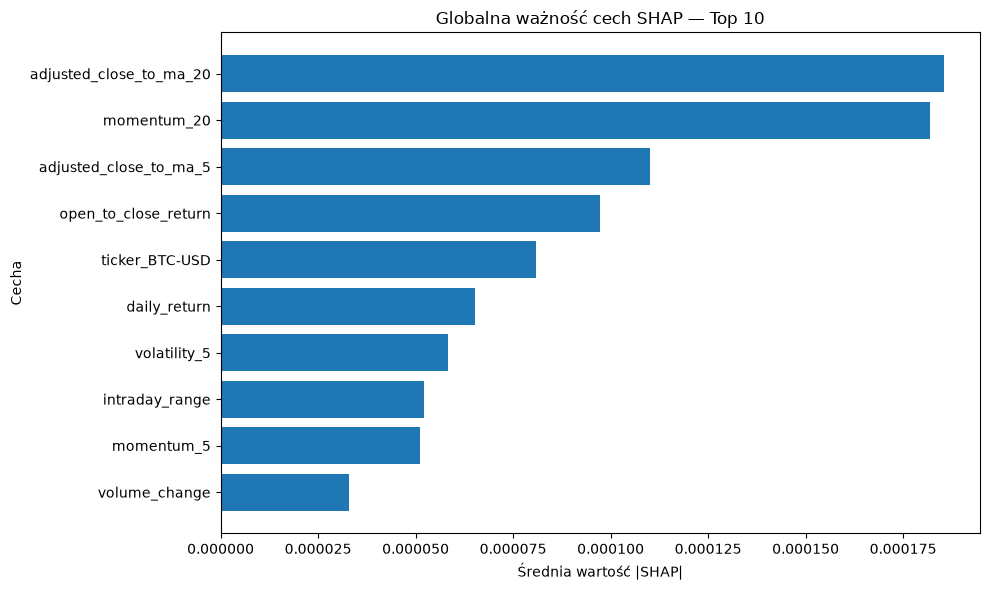

In [30]:
top_features = global_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["mean_absolute_shap_value"][::-1],
)

plt.xlabel("Średnia wartość |SHAP|")
plt.ylabel("Cecha")
plt.title("Globalna ważność cech SHAP — Top 10")

plt.tight_layout()

plt.show()

## 5. Szczegółowe wartości SHAP

Artefakt zawiera również pełną macierz wkładów SHAP dla obserwacji
walidacyjnych.

Pozwala ona analizować:

- rozkład wpływów;
- stabilność oddziaływania cech;
- pojedyncze przypadki predykcji.

Nie jest to jednak ponowne trenowanie ani ponowna interpretacja modelu.
Notebook wykorzystuje wyłącznie zapisane wyniki backendu.

In [31]:
shap_values_path = XAI_DIR / "global_shap_contributions.csv"

shap_frame = pd.read_csv(shap_values_path)

print("Shape:", shap_frame.shape)

display(shap_frame.head())

Shape: (400, 19)


,observation_index,daily_return,volume_change,volatility_5,volatility_20,momentum_5,momentum_20,adjusted_close_to_ma_5,adjusted_close_to_ma_20,intraday_range,open_to_close_return,ticker_AGG,ticker_BTC-USD,ticker_EPOL,ticker_GLD,ticker_QQQ,ticker_SPY,ticker_VGK,ticker_VT
0,3655,0.000034,0.000009,-0.000025,-0.000011,0.000017,-0.000114,-0.000065,-0.000106,0.000029,-0.000042,-1.163091e-06,-0.000022,0.000004,1.056334e-07,-2.516409e-06,1.105987e-06,-6.630429e-06,1.809643e-07
1,3093,0.000033,0.000004,-0.000015,0.000005,-0.000008,-0.000105,0.000003,-0.000070,-0.000007,-0.000065,1.635063e-06,-0.000057,0.000002,3.458020e-07,-2.170400e-06,1.875438e-07,3.550456e-07,1.809643e-07
2,6,0.000029,0.000019,-0.000018,-0.000004,-0.000029,-0.000107,-0.000054,-0.000075,0.000017,-0.000054,-1.052574e-05,-0.000042,0.000004,1.039095e-06,-2.058707e-06,9.941818e-09,1.750065e-07,0.000000e+00
3,3662,0.000030,-0.000006,-0.000009,0.000003,-0.000017,-0.000090,-0.000067,-0.000062,0.000009,-0.000054,2.746511e-08,-0.000046,0.000001,9.865217e-07,-9.725002e-07,9.941818e-09,-8.126451e-06,0.000000e+00
4,577,0.000050,0.000095,-0.000303,0.000024,-0.000194,-0.000074,0.002403,0.000397,0.000184,-0.000026,3.026750e-06,0.000544,0.000026,2.420793e-06,2.829062e-06,1.653054e-06,2.268555e-06,9.048214e-08


In [32]:
feature_columns = [
    column for column in shap_frame.columns if column != "observation_index"
]

shap_summary = (
    shap_frame[feature_columns]
    .abs()
    .mean()
    .sort_values(ascending=False)
    .rename("mean_absolute_shap")
    .reset_index()
)

shap_summary.columns = [
    "feature",
    "mean_absolute_shap",
]

display(shap_summary.head(10))

,feature,mean_absolute_shap
0,adjusted_close_to_ma_20,0.000185
1,momentum_20,0.000182
2,adjusted_close_to_ma_5,0.000110
3,open_to_close_return,0.000097
4,ticker_BTC-USD,0.000081
5,daily_return,0.000065
6,volatility_5,0.000058
7,intraday_range,0.000052
8,momentum_5,0.000051
9,volume_change,0.000033


## Wniosek z analizy globalnej

Globalny ranking SHAP pozwala odpowiedzieć na pytanie:

> "Które informacje model najczęściej wykorzystywał?"

Nie odpowiada natomiast na pytanie:

> "Które czynniki powodują przyszłe zwroty?"

Model może wykorzystywać:

- zależności historyczne;
- korelacje;
- specyficzne wzorce obecne w danych treningowych.

Dlatego SHAP jest narzędziem kontroli modelu, a nie dowodem ekonomicznej przyczynowości.

## 6. Lokalne wyjaśnienie pojedynczej predykcji

Globalne SHAP pokazuje ogólne zachowanie modelu.

Lokalne SHAP odpowiada na pytanie:

> "Dlaczego model dla tej konkretnej obserwacji przewidział taki wynik?"

Analizujemy reprezentatywną obserwację zapisaną w artefakcie XAI.

Wyjaśnienie składa się z:

- wartości bazowej modelu;
- wkładów poszczególnych cech;
- końcowej predykcji;
- rzeczywistego wyniku obserwacji.

Należy pamiętać, że SHAP opisuje sposób działania modelu,
a nie rzeczywiste przyczyny ruchu rynku.

In [33]:
local_shap = xai_result["local_shap"]

local_metadata = xai_result["metadata"]

print("Ticker:", local_metadata["local_ticker"])
print("Data cech:", local_metadata["local_date"])
print("Data celu:", local_metadata["local_target_date"])

print()

print("Rzeczywisty zwrot:", local_metadata["local_actual"])

print("Predykcja modelu:", local_metadata["local_prediction"])

print("Wartość bazowa:", local_shap["base_value"])

print("Rekonstrukcja SHAP:", local_shap["reconstructed_prediction"])

Ticker: BTC-USD
Data cech: 2022-06-12T00:00:00
Data celu: 2022-06-13T00:00:00

Rzeczywisty zwrot: -0.159747260276172
Predykcja modelu: 0.0017502030309710385
Wartość bazowa: 0.0006529016959202627
Rekonstrukcja SHAP: 0.0017502029951165592


In [34]:
local_features = pd.DataFrame(local_shap["features"])

local_features = local_features.sort_values(
    by="shap_value",
    key=lambda x: x.abs(),
    ascending=False,
).reset_index(drop=True)

display(local_features)

,feature,feature_value,shap_value
0,adjusted_close_to_ma_5,-0.074172,2.886294e-03
1,intraday_range,0.065017,-6.472202e-04
2,ticker_BTC-USD,1.000000,-5.163627e-04
3,volatility_20,0.032945,-3.156795e-04
4,momentum_20,-0.080287,-2.251179e-04
5,volume_change,0.253854,-2.015991e-04
6,adjusted_close_to_ma_20,-0.101416,1.690457e-04
7,momentum_5,-0.140997,-4.339294e-05
8,ticker_EPOL,0.000000,2.577749e-05
9,daily_return,-0.056351,-2.220810e-05


## Interpretacja wkładów SHAP

Znaki wartości SHAP oznaczają kierunek wpływu:

- dodatnia wartość SHAP zwiększa predykcję modelu;
- ujemna wartość SHAP zmniejsza predykcję modelu.

Siła wpływu jest określona przez wartość bezwzględną.

Przykład:

- `SHAP = +0.0004` oznacza pozytywny wpływ;
- `SHAP = -0.0004` oznacza negatywny wpływ;
- większa wartość bezwzględna oznacza większe znaczenie dla tej predykcji.

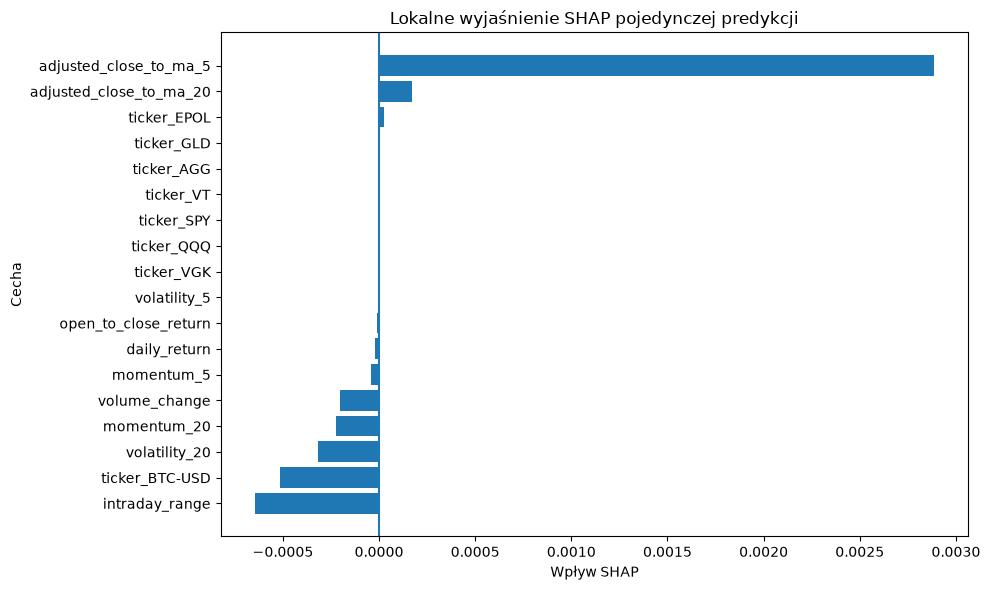

In [35]:
plt.figure(figsize=(10, 6))

plot_frame = local_features.copy()

plot_frame = plot_frame.sort_values("shap_value")

plt.barh(
    plot_frame["feature"],
    plot_frame["shap_value"],
)

plt.axvline(0)

plt.xlabel("Wpływ SHAP")
plt.ylabel("Cecha")

plt.title("Lokalne wyjaśnienie SHAP pojedynczej predykcji")

plt.tight_layout()

plt.show()

## Sprawdzenie rekonstrukcji predykcji

SHAP powinien spełniać zależność:

\[
prediction \approx base\ value + \sum SHAP_i
\]

Pozwala to sprawdzić poprawność zapisanych artefaktów.

In [36]:
shap_sum = local_shap["base_value"] + sum(
    item["shap_value"] for item in local_shap["features"]
)

print(
    "Predykcja z rekonstrukcji:",
    shap_sum,
)

print(
    "Predykcja zapisana:",
    local_shap["prediction"],
)

print(
    "Różnica:",
    abs(shap_sum - local_shap["prediction"]),
)

Predykcja z rekonstrukcji: 0.0017502029951165588
Predykcja zapisana: 0.001750203030971039
Różnica: 3.5854480192124005e-11


## 7. Partial Dependence oraz Accumulated Local Effects

SHAP pokazuje wpływ cechy na predykcję.

PDP i ALE pokazują natomiast zależność:

> "Jak zmienia się predykcja modelu, gdy zmienia się wartość konkretnej cechy?"

### Partial Dependence (PDP)

PDP oblicza średnią predykcję modelu dla różnych wartości wybranej cechy.

Zalety:

- prosta interpretacja;
- łatwa wizualizacja zależności.

Ograniczenia:

- może być zaburzony przez korelacje pomiędzy cechami;
- zakłada możliwość obserwacji kombinacji wartości, które mogą nie występować w danych.

### Accumulated Local Effects (ALE)

ALE analizuje lokalne zmiany predykcji w rzeczywistych zakresach danych.

Zalety:

- lepiej radzi sobie z korelacją cech;
- wykorzystuje faktycznie występujące obserwacje.

Obie metody opisują zachowanie modelu,
a nie zależności przyczynowe.

In [ ]:
pdp_data = xai_result["partial_dependence"]

print("Dostępne cechy PDP:")

for feature in pdp_data:
    print("-", feature)

Dostępne cechy PDP:
- adjusted_close_to_ma_20
- adjusted_close_to_ma_5
- momentum_20
- open_to_close_return


In [ ]:
selected_feature = list(pdp_data.keys())[0]

selected_pdp = pd.DataFrame(
    {
        "feature_value": pdp_data[selected_feature]["feature_values"],
        "average_prediction": pdp_data[selected_feature]["average_predictions"],
    }
)

display(selected_pdp)

,feature_value,average_prediction
0,-0.063618,0.000564
1,-0.056867,0.000506
2,-0.050115,0.000508
3,-0.043364,0.000488
4,-0.036613,0.000488
5,-0.029861,0.000514
6,-0.023110,0.000507
7,-0.016359,0.000504
8,-0.009607,0.000501
9,-0.002856,0.000508


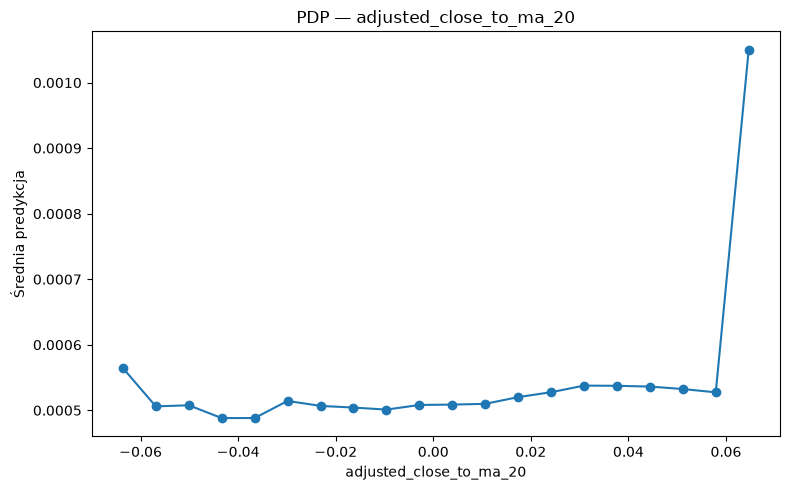

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    selected_pdp["feature_value"],
    selected_pdp["average_prediction"],
    marker="o",
)

plt.xlabel(selected_feature)

plt.ylabel("Średnia predykcja")

plt.title(f"PDP — {selected_feature}")

plt.tight_layout()

plt.show()

## Analiza wszystkich dostępnych PDP

Artefakt zawiera PDP dla wybranych najważniejszych cech.

Przegląd wszystkich wykresów pozwala sprawdzić:

- czy zależność jest monotoniczna;
- czy model reaguje liniowo;
- czy występują punkty przełomowe;
- czy reakcja modelu jest niestabilna.

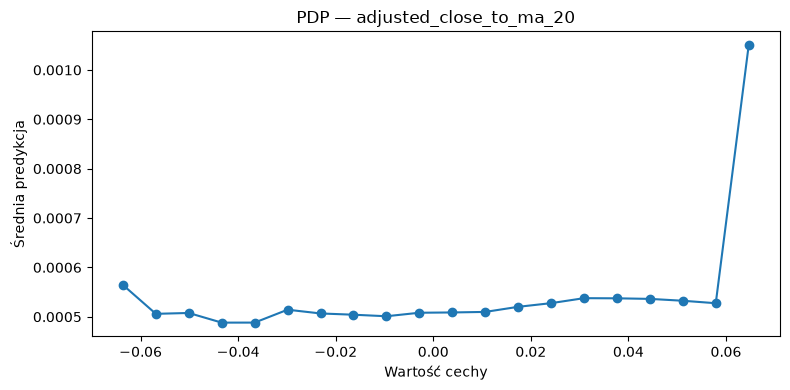

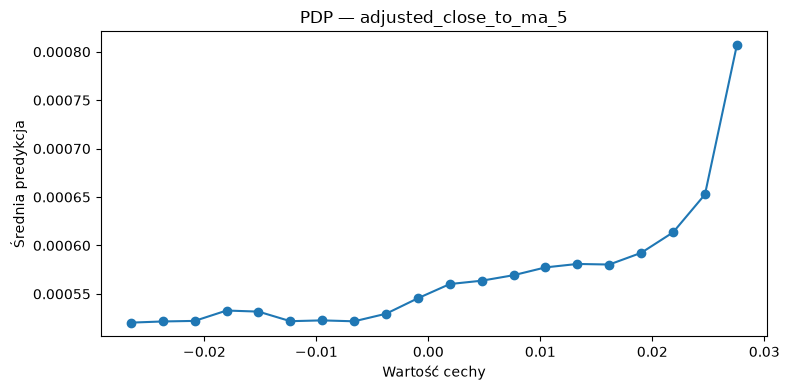

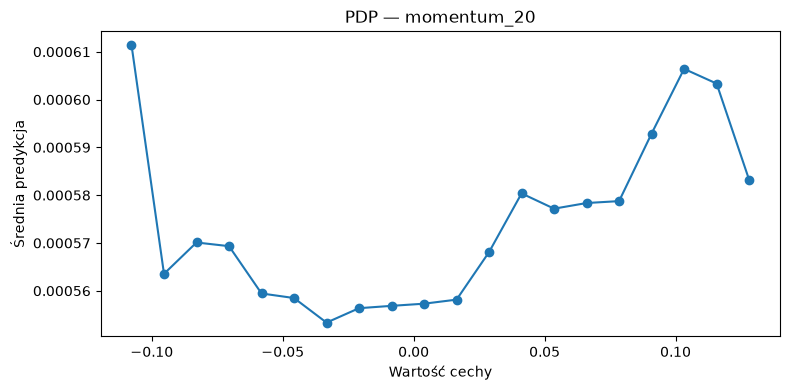

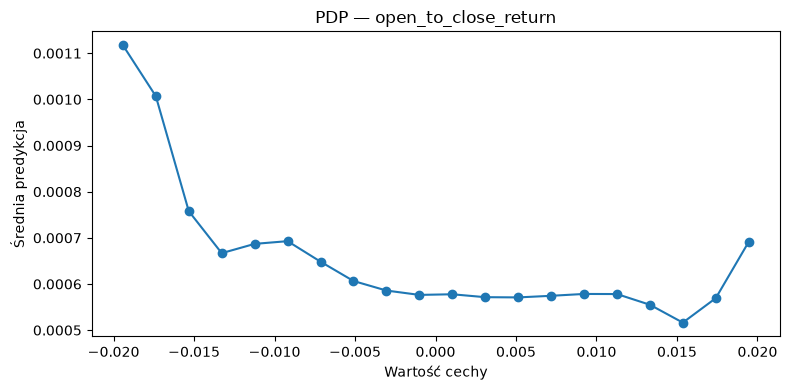

In [ ]:
for feature, values in pdp_data.items():
    frame = pd.DataFrame(
        {
            "feature_value": values["feature_values"],
            "average_prediction": values["average_predictions"],
        }
    )

    plt.figure(figsize=(8, 4))

    plt.plot(
        frame["feature_value"],
        frame["average_prediction"],
        marker="o",
    )

    plt.title(f"PDP — {feature}")

    plt.xlabel("Wartość cechy")

    plt.ylabel("Średnia predykcja")

    plt.tight_layout()

    plt.show()

## 8. Accumulated Local Effects (ALE)

ALE pokazuje lokalny wpływ zmian wartości cechy.

Interpretacja:

- wartości dodatnie oznaczają obszary zwiększające predykcję;
- wartości ujemne oznaczają obszary zmniejszające predykcję;
- wielkość efektu opisuje siłę reakcji modelu.

ALE jest często bardziej stabilne niż PDP
dla danych finansowych, gdzie cechy są ze sobą powiązane.

In [ ]:
ale_data = xai_result["accumulated_local_effects"]

print("Dostępne cechy ALE:")

for feature in ale_data:
    print("-", feature)

Dostępne cechy ALE:
- adjusted_close_to_ma_20
- adjusted_close_to_ma_5
- momentum_20
- open_to_close_return


In [ ]:
selected_feature = list(ale_data.keys())[0]

selected_ale = pd.DataFrame(
    {
        "bin_center": ale_data[selected_feature]["bin_centers"],
        "accumulated_effect": ale_data[selected_feature]["accumulated_effects"],
        "sample_count": ale_data[selected_feature]["sample_counts"],
    }
)

display(selected_ale)

,bin_center,accumulated_effect,sample_count
0,-0.174450,-0.000352,479
1,-0.033895,-0.000341,478
2,-0.018645,-0.000343,479
3,-0.009230,-0.000345,478
4,-0.001449,-0.000343,479
5,0.006599,-0.000343,479
6,0.015159,-0.000339,478
7,0.024794,-0.000330,478
8,0.038708,-0.000336,479
9,0.138007,0.003070,479


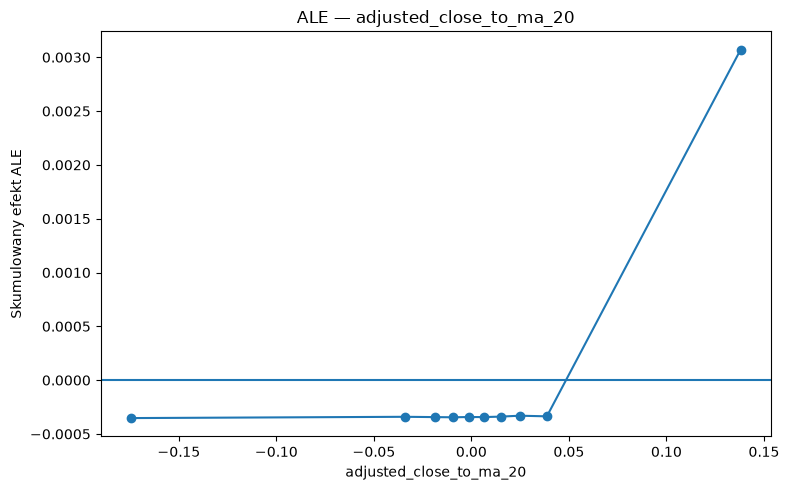

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    selected_ale["bin_center"],
    selected_ale["accumulated_effect"],
    marker="o",
)

plt.axhline(0)

plt.xlabel(selected_feature)

plt.ylabel("Skumulowany efekt ALE")

plt.title(f"ALE — {selected_feature}")

plt.tight_layout()

plt.show()

# Podsumowanie XAI

Wykorzystane metody:

| Metoda | Odpowiada na pytanie |
|---|---|
| SHAP global | Które cechy model wykorzystuje najczęściej? |
| SHAP lokal | Dlaczego konkretna predykcja wygląda tak? |
| PDP | Jak średnio model reaguje na zmianę cechy? |
| ALE | Jak lokalnie zmienia się predykcja w rzeczywistych danych? |

Najważniejsze ograniczenie:

Interpretacja modelu nie oznacza odkrycia zależności przyczynowych.

XAI służy do:

- kontroli jakości modelu;
- wykrywania nietypowych zachowań;
- zwiększenia transparentności;
- wsparcia analizy decyzji.

Nie zastępuje oceny jakości prognostycznej modelu.